### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

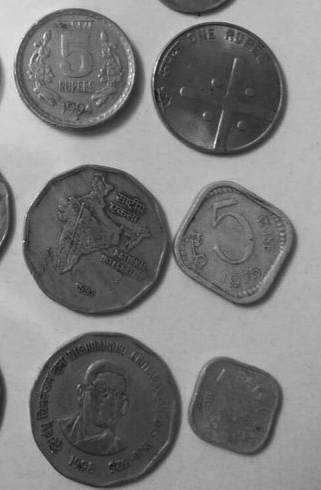

In [4]:
coins = cv2.imread('../Materialy/Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

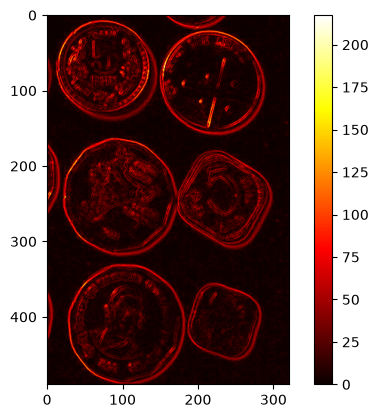

In [5]:
mag = np.zeros(coins.shape, dtype=np.float32)
for i in range(len(coins)):
    for j in range(len(coins[i])):
        gx = (int(coins[i][j+1]) - int(coins[i][j-1])) if j > 0 and j < len(coins[i])-1 else 0
        gy = (int(coins[i+1][j]) - int(coins[i-1][j])) if i > 0 and i < len(coins)-1 else 0
        mag[i][j] = np.sqrt(gx**2 + gy**2)



plt.imshow(mag, cmap='hot'); plt.colorbar();

- Gradienty są bliskie 0 dla tła oraz w środku monet gdzie nie ma szczegółów. Czyli tam gdzie nie ma krawędzi.

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

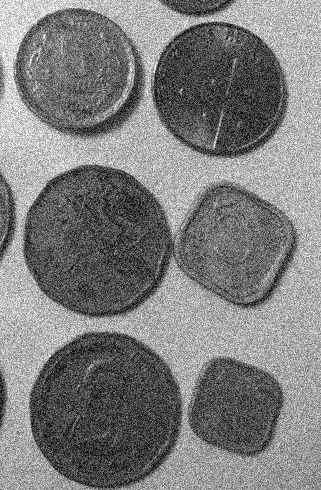

In [6]:
coins_noise = cv2.imread('../Materialy/Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

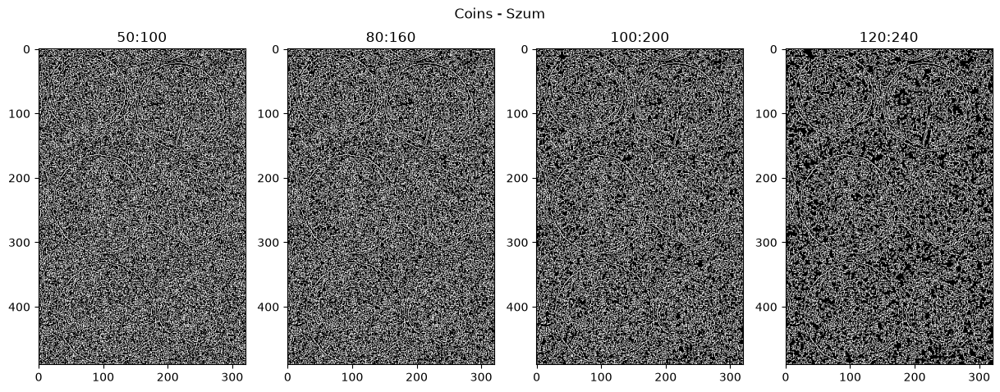

In [7]:
_, axs = plt.subplots(1, 4, figsize=(15, 5))
plt.suptitle('Coins - Szum')
thresholds = [50, 80, 100, 120]
for i in range(len(thresholds)):
    threshold = thresholds[i]
    axs[i].imshow(cv2.Canny(coins_noise, threshold1=threshold, threshold2=threshold*2), cmap='gray')
    axs[i].set_title(f'{threshold}:{threshold*2}')

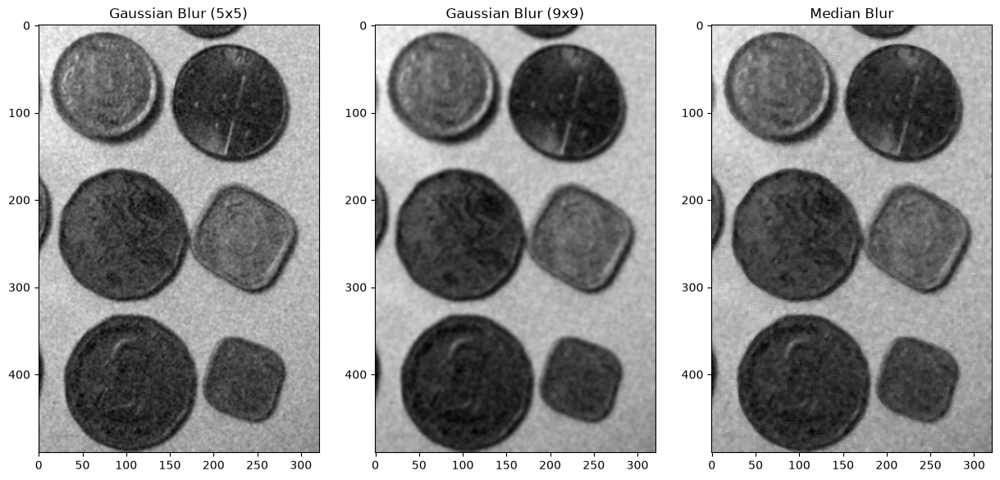

In [8]:
coins_gaus_5 = cv2.GaussianBlur(coins_noise, ksize=(5, 5), sigmaX=0)
coins_gaus_9 = cv2.GaussianBlur(coins_noise, ksize=(9, 9), sigmaX=0)
coins_median = cv2.medianBlur(coins_noise, ksize=5)

_, axs = plt.subplots(1, 3, figsize=(15, 8))
axs[0].imshow(coins_gaus_5, cmap='gray'); axs[0].set_title('Gaussian Blur (5x5)')
axs[1].imshow(coins_gaus_9, cmap='gray'); axs[1].set_title('Gaussian Blur (9x9)')
axs[2].imshow(coins_median, cmap='gray'); axs[2].set_title('Median Blur');


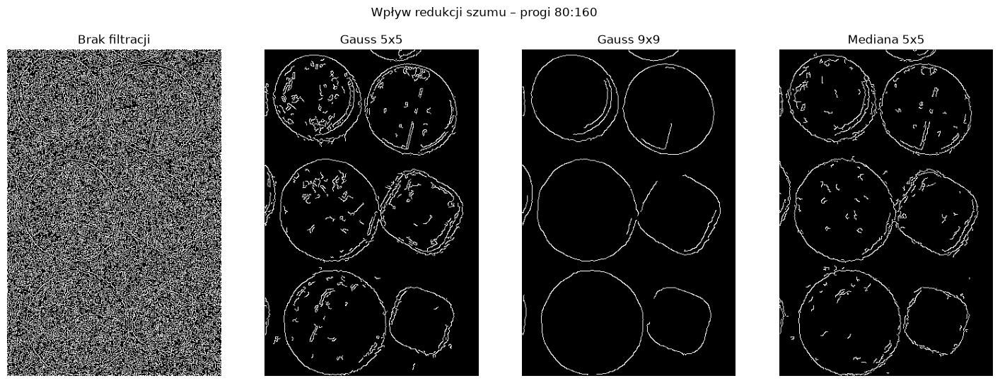

In [9]:
filtry = {
    'Brak filtracji': coins_noise,
    'Gauss 5x5': coins_gaus_5,
    'Gauss 9x9': coins_gaus_9,
    'Mediana 5x5': coins_median,
}
_, axs = plt.subplots(1, 4, figsize=(18, 6))
plt.suptitle('Wpływ redukcji szumu – progi 80:160')
for ax, (nazwa, img) in zip(axs, filtry.items()):
    ax.imshow(cv2.Canny(img, 80, 160), cmap='gray')
    ax.set_title(nazwa)
    ax.axis('off')
plt.show()


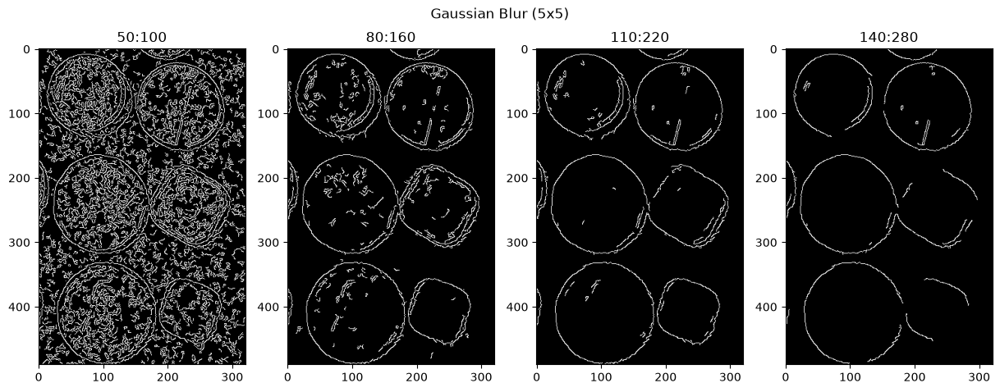

In [10]:
# Badanie progów 
_, axs = plt.subplots(1, 4, figsize=(15, 5))
plt.suptitle('Gaussian Blur (5x5)')
thresholds = [50, 80, 110, 140]
for i in range(len(thresholds)):
    threshold = thresholds[i]
    axs[i].imshow(cv2.Canny(coins_gaus_5, threshold1=threshold, threshold2=threshold*2), cmap='gray')
    axs[i].set_title(f'{threshold}:{threshold*2}')

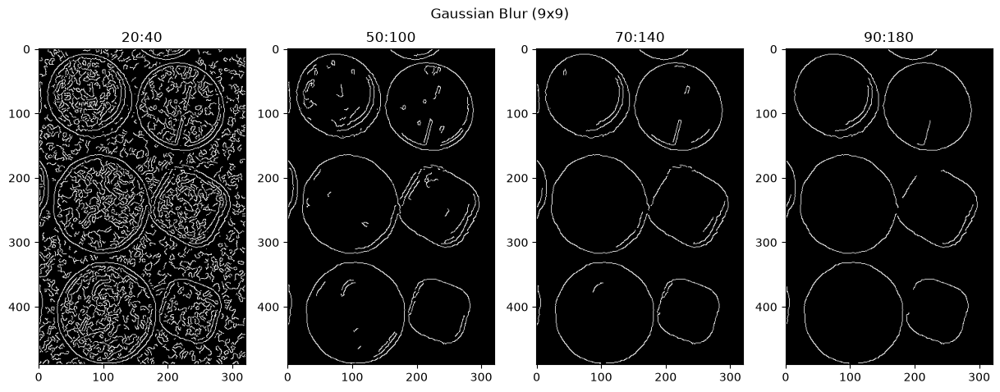

In [11]:
# Badanie progów 
_, axs = plt.subplots(1, 4, figsize=(15, 5))
plt.suptitle('Gaussian Blur (9x9)')
thresholds = [20, 50, 70, 90]
for i in range(len(thresholds)):
    threshold = thresholds[i]
    axs[i].imshow(cv2.Canny(coins_gaus_9, threshold1=threshold, threshold2=threshold*2), cmap='gray')
    axs[i].set_title(f'{threshold}:{threshold*2}')

- Gauss 5×5 i mediana 5×5 dają podobne wyniki. Natomiast Gauss 9×9 usuwa szum niemal całkowicie już przy niższych progach.
- Progi: zbyt niskie przepuszczają szum, zbyt wysokie rwą kontury.
- Filtr i progi są ze sobą powiązane. Silniejsze rozmycie tłumi szum, ale też „rozsmarowuje” krawędzie na więcej pikseli, przez co ich gradient maleje. Dlatego przy silniejszym filtrze trzeba stosować niższe progi, i nie ma jednej uniwersalnej pary progów niezależnej od filtracji.

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

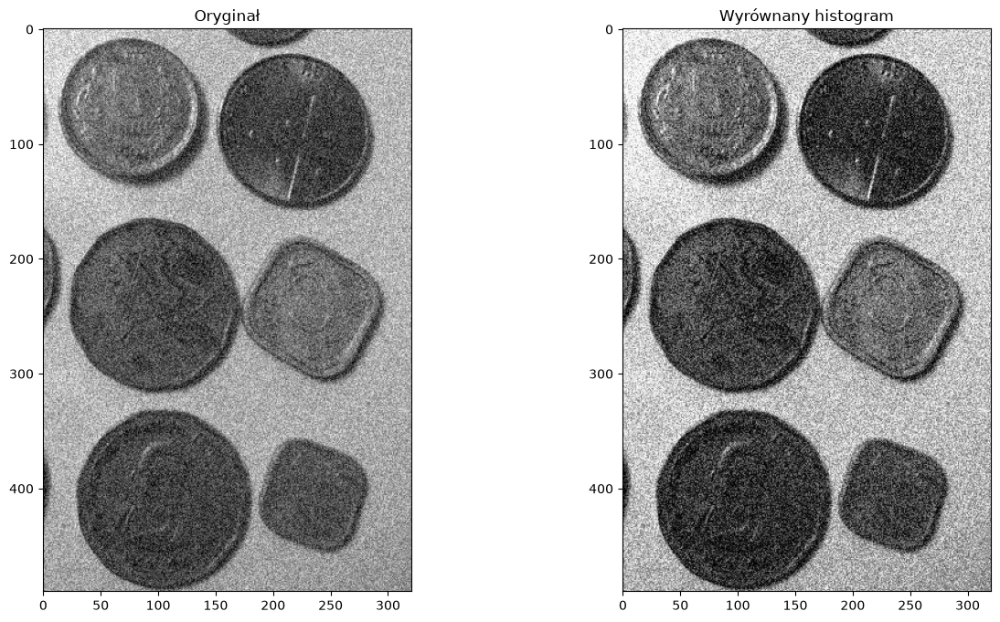

In [12]:
_, axs = plt.subplots(1, 2, figsize=(15, 8))
axs[0].imshow(coins_noise, cmap='gray'); axs[0].set_title('Oryginał')
coins_eq = cv2.equalizeHist(coins_noise) 
axs[1].imshow(coins_eq, cmap='gray'); axs[1].set_title('Wyrównany histogram');

Text(0.5, 1.0, 'Histogram wyrównany')

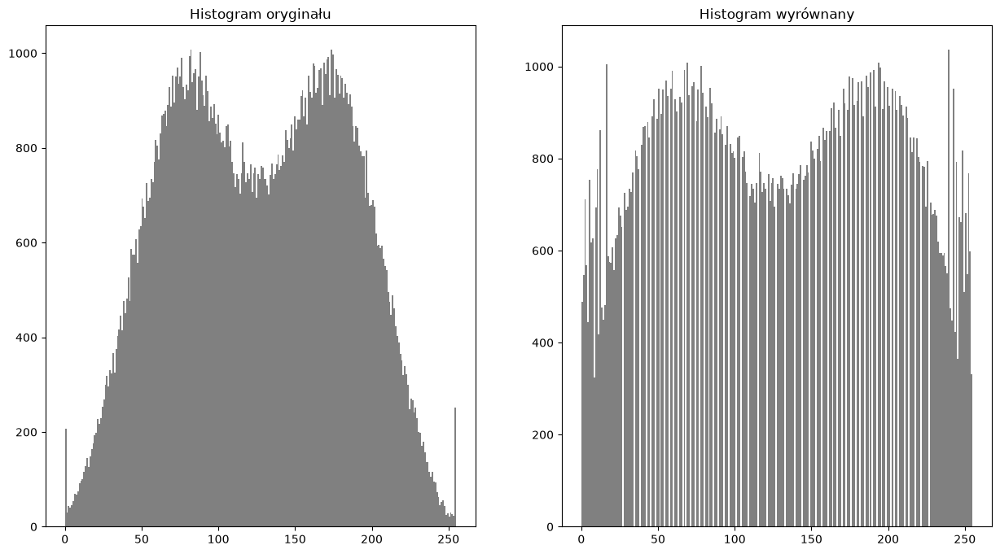

In [13]:
_, axs = plt.subplots(1, 2, figsize=(15, 8))
axs[0].hist(coins_noise.ravel(), bins=256, range=(0, 255), color='gray')
axs[0].set_title('Histogram oryginału')
axs[1].hist(coins_eq.ravel(), bins=256, range=(0, 255), color='gray')
axs[1].set_title('Histogram wyrównany')

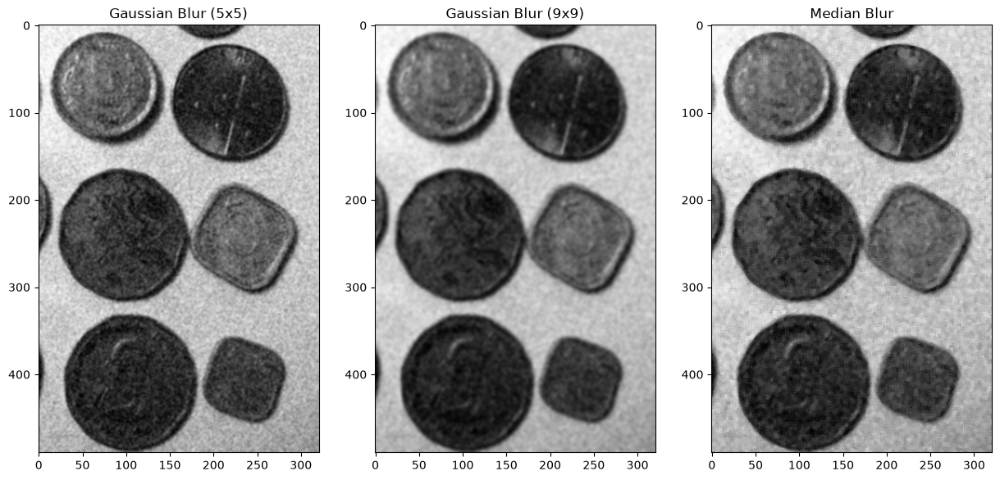

In [14]:
coins_eq_gaus_5 = cv2.GaussianBlur(coins_eq, ksize=(5, 5), sigmaX=0)
coins_eq_gaus_9 = cv2.GaussianBlur(coins_eq, ksize=(9, 9), sigmaX=0)
coins_eq_median = cv2.medianBlur(coins_eq, ksize=5)

_, axs = plt.subplots(1, 3, figsize=(15, 8))
axs[0].imshow(coins_eq_gaus_5, cmap='gray'); axs[0].set_title('Gaussian Blur (5x5)')
axs[1].imshow(coins_eq_gaus_9, cmap='gray'); axs[1].set_title('Gaussian Blur (9x9)')
axs[2].imshow(coins_eq_median, cmap='gray'); axs[2].set_title('Median Blur');

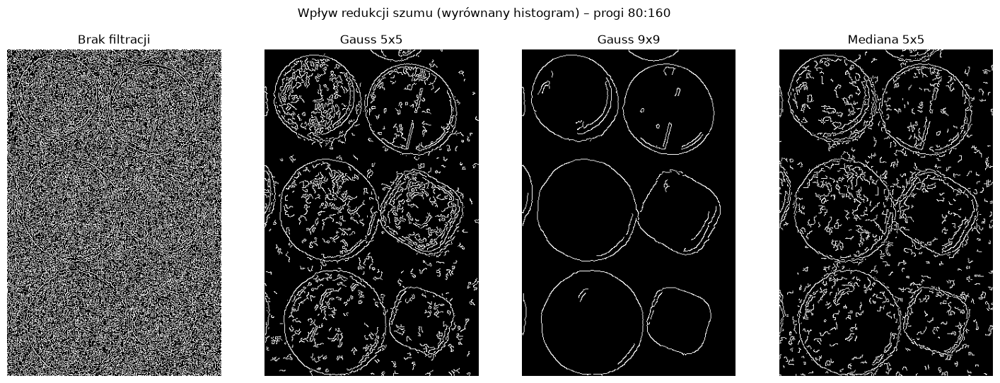

In [15]:
filtry_eq = {
    'Brak filtracji': coins_eq,
    'Gauss 5x5': coins_eq_gaus_5,
    'Gauss 9x9': coins_eq_gaus_9,
    'Mediana 5x5': coins_eq_median,
}
_, axs = plt.subplots(1, 4, figsize=(18, 6))
plt.suptitle('Wpływ redukcji szumu (wyrównany histogram) – progi 80:160')
for ax, (nazwa, img) in zip(axs, filtry_eq.items()):
    ax.imshow(cv2.Canny(img, 80, 160), cmap='gray')
    ax.set_title(nazwa)
    ax.axis('off')
plt.show()

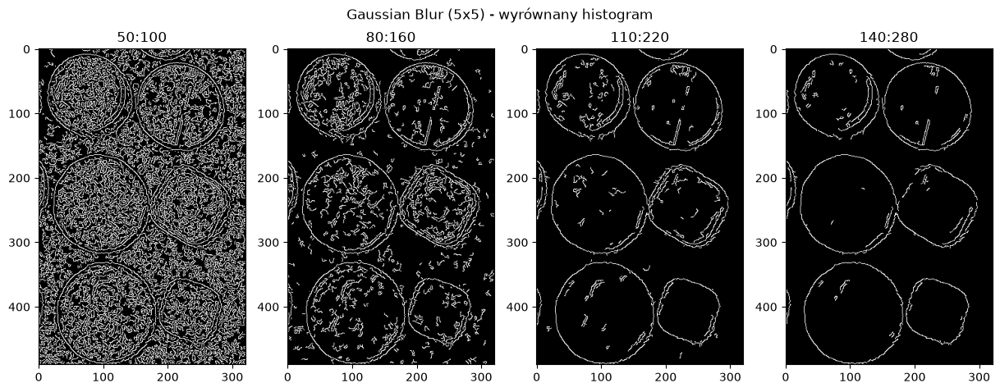

In [16]:
# Badanie progów 
_, axs = plt.subplots(1, 4, figsize=(15, 5))
plt.suptitle('Gaussian Blur (5x5) - wyrównany histogram')
thresholds = [50, 80, 110, 140]
for i in range(len(thresholds)):
    threshold = thresholds[i]
    axs[i].imshow(cv2.Canny(coins_eq_gaus_5, threshold1=threshold, threshold2=threshold*2), cmap='gray')
    axs[i].set_title(f'{threshold}:{threshold*2}')

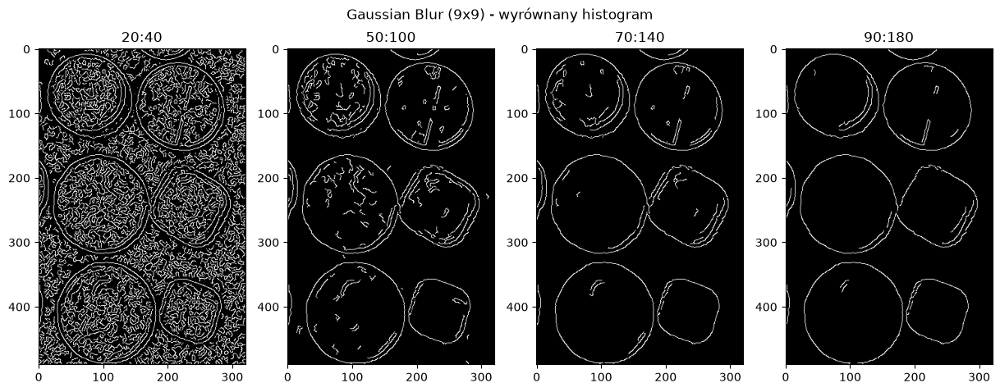

In [17]:
# Badanie progów 
_, axs = plt.subplots(1, 4, figsize=(15, 5))
plt.suptitle('Gaussian Blur (9x9) - wyrównany histogram')
thresholds = [20, 50, 70, 90]
for i in range(len(thresholds)):
    threshold = thresholds[i]
    axs[i].imshow(cv2.Canny(coins_eq_gaus_9, threshold1=threshold, threshold2=threshold*2), cmap='gray')
    axs[i].set_title(f'{threshold}:{threshold*2}')

- Wyrównanie histogramu zwiększa kontrast, ale jest przekształceniem samych jasności pikseli – nie rozróżnia, czy zmiana jasności pochodzi od krawędzi, czy od szumu. Wzmacnia więc w podobnym stopniu jedno i drugie.
- Bez filtracji wynik jest taki sam jak w zad. 2 – detektor zaznacza praktycznie sam szum, wyrównanie niczego nie poprawia.
- Przy tych samych progach na wyrównanym obrazie wykrywanych jest więcej krawędzi: zarówno fałszywych (szum – szczególnie widoczne dla Gaussa 5×5 i mediany), jak i detali reliefu wewnątrz monet. Efekt jest podobny do obniżenia progów.
- Dla Gaussa 9×9 kontury monet pozostają ciągłe nawet przy progach 90:180, przy których przed wyrównaniem już się rwały. Optymalne progi przesuwają się więc w górę.
- Wyrównanie histogramu nie poprawia jakości detekcji krawędzi – gradienty krawędzi i szumu rosną proporcjonalnie, więc ich wzajemny stosunek się nie zmienia, zmienia się tylko skala, do której trzeba dopasować progi. Po ich podniesieniu wyniki są porównywalne z zad. 2. Kluczowa pozostaje redukcja szumu.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

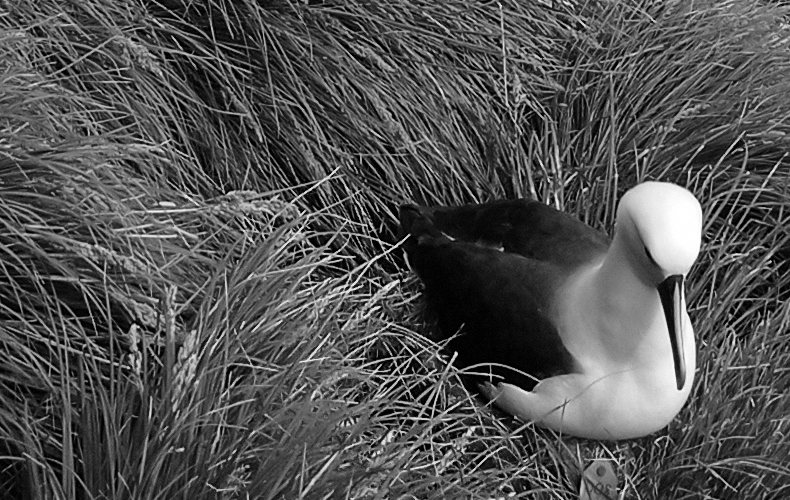

In [18]:
albatross_single = cv2.imread('../Materialy/albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

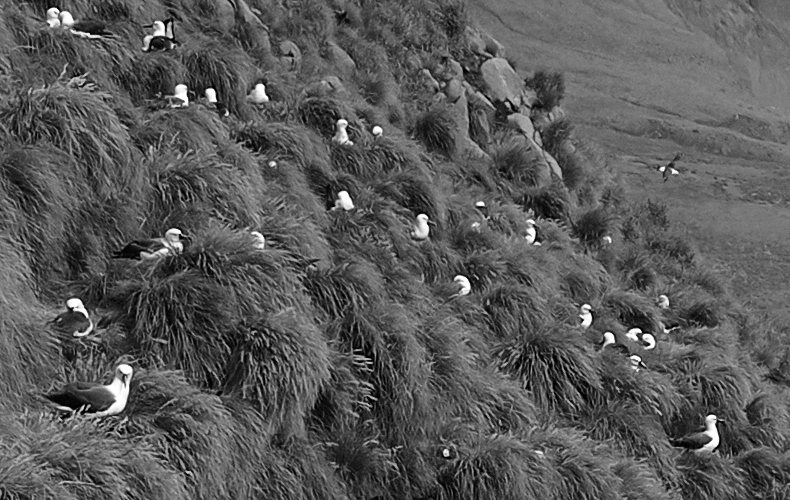

In [19]:
albatross_crowd = cv2.imread('../Materialy/albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

In [20]:
def lut_hist(img, p_docelowy):
    cdf_we = np.cumsum(np.bincount(img.ravel(), minlength=256)) / img.size
    cdf_doc = np.cumsum(p_docelowy) / p_docelowy.sum()
    return np.clip(np.searchsorted(cdf_doc, cdf_we), 0, 255).astype(np.uint8)  # l1 → l2

def transform_hist(img, p_docelowy):
    return cv2.LUT(img, lut_hist(img, p_docelowy))

def otsu(img):
    t, binarny = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return t, binarny

def pokaz_otsu(obrazy):
    # obrazy: {tytuł: obraz} – każdy w osobnym wierszu: obraz | histogram z progiem Otsu | wynik Otsu
    _, axs = plt.subplots(len(obrazy), 3, figsize=(22, 4.5 * len(obrazy)), squeeze=False)
    for row, (tytul, img) in zip(axs, obrazy.items()):
        t, binarny = otsu(img)

        row[0].imshow(img, cmap='gray', vmin=0, vmax=255)
        row[0].set_title(tytul)
        row[0].axis('off')

        row[1].hist(img.ravel(), bins=256, range=(0, 256), color='gray')
        row[1].axvline(t, color='r')
        row[1].set_title(f'histogram, próg Otsu = {t:.0f}')

        row[2].imshow(binarny, cmap='gray')
        row[2].set_title(f'Otsu: obiekt = {(binarny > 0).mean():.1%} pikseli')
        row[2].axis('off')
    plt.tight_layout()
    plt.show()

**Punkt odniesienia – Otsu bez transformacji**

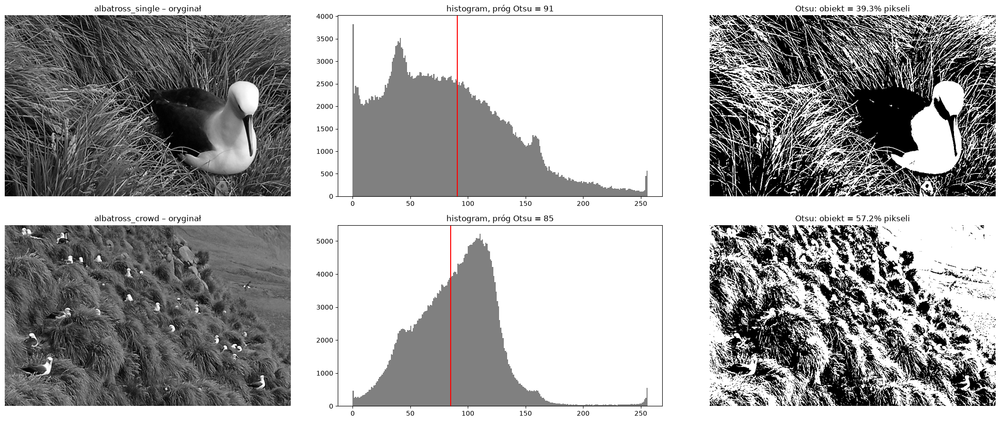

In [21]:
pokaz_otsu({
    'albatross_single – oryginał': albatross_single,
    'albatross_crowd – oryginał': albatross_crowd,
})

**Wybrany rozkład docelowy – dwumodalny**

Otsu zakłada, że piksele należą do dwóch klas (tło i obiekt), czyli że histogram ma dwa garby. Dlatego rozkładem docelowym jest suma dwóch rozkładów Gaussa:
- `mu1`, `sigma1` – położenie i szerokość garbu tła (ciemnego),
- `mu2`, `sigma2` – położenie i szerokość garbu obiektu (jasnego),
- `w` – udział garbu obiektu, czyli jaka część pikseli ma do niego trafić.

Parametry bazowe: `mu1 = 60`, `sigma1 = 15`, `mu2 = 200`, `sigma2 = 15`, `w = 0.05`.

In [22]:
l = np.arange(256)

def gauss(mu, sigma):
    return np.exp(-(l - mu)**2 / (2 * sigma**2))

def two_peaks(mu1=60, sigma1=15, mu2=200, sigma2=15, w=0.05):
    # w - jaka część pikseli ma trafić do drugiego (jasnego) garbu
    g1 = gauss(mu1, sigma1)
    g2 = gauss(mu2, sigma2)
    return (1 - w) * g1 / g1.sum() + w * g2 / g2.sum()

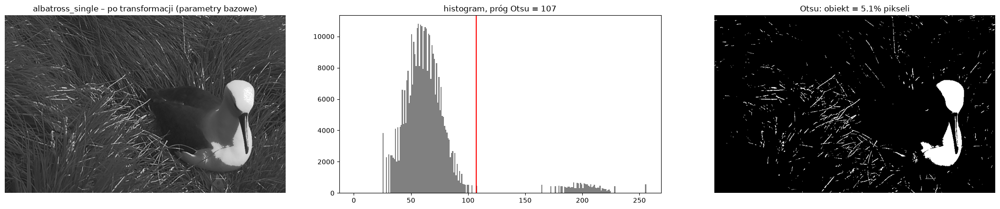

In [23]:
pokaz_otsu({'albatross_single – po transformacji (parametry bazowe)': transform_hist(albatross_single, two_peaks())})

**Badanie parametrów rozkładu dwumodalnego**

W każdym badaniu zmieniany jest jeden parametr, pozostałe mają wartości bazowe. Na każdym wykresie:
- lewy górny – rozkład docelowy dla każdej wartości parametru; linia przerywana w tym samym kolorze to próg Otsu po transformacji,
- prawy górny – krzywa przekształcenia jasności (LUT),
- dolny wiersz – wynik binaryzacji Otsu i procent pikseli uznanych za obiekt.

In [24]:
def badaj_parametr(img, tytul, warianty):
    # warianty: {opis: rozkład docelowy}
    n = len(warianty)
    fig = plt.figure(figsize=(5 * n, 8))
    gs = fig.add_gridspec(2, n)
    ax_rozklad = fig.add_subplot(gs[0, :n // 2])
    ax_lut = fig.add_subplot(gs[0, n // 2:])
    for k, (nazwa, p) in enumerate(warianty.items()):
        kolor = f'C{k}'
        lut = lut_hist(img, p)
        t, binarny = otsu(cv2.LUT(img, lut))

        ax_rozklad.plot(l, p / p.sum(), color=kolor, label=nazwa)
        ax_rozklad.axvline(t, color=kolor, linestyle='--')
        ax_lut.plot(lut, color=kolor, label=nazwa)

        ax = fig.add_subplot(gs[1, k])
        ax.imshow(binarny, cmap='gray')
        ax.set_title(f'{nazwa}\nobiekt: {(binarny > 0).mean():.1%} pikseli', color=kolor)
        ax.axis('off')

    ax_rozklad.set_title('Rozkład docelowy (przerywane: próg Otsu)')
    ax_rozklad.set_xlabel('jasność')
    ax_rozklad.legend()
    ax_lut.plot([0, 255], [0, 255], 'k:', label='bez zmian')
    ax_lut.set_title('Przekształcenie jasności (LUT)')
    ax_lut.set_xlabel('jasność wejściowa')
    ax_lut.set_ylabel('jasność wyjściowa')
    ax_lut.legend()
    fig.suptitle(tytul, fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

**Badanie 1: waga garbu obiektu `w`**

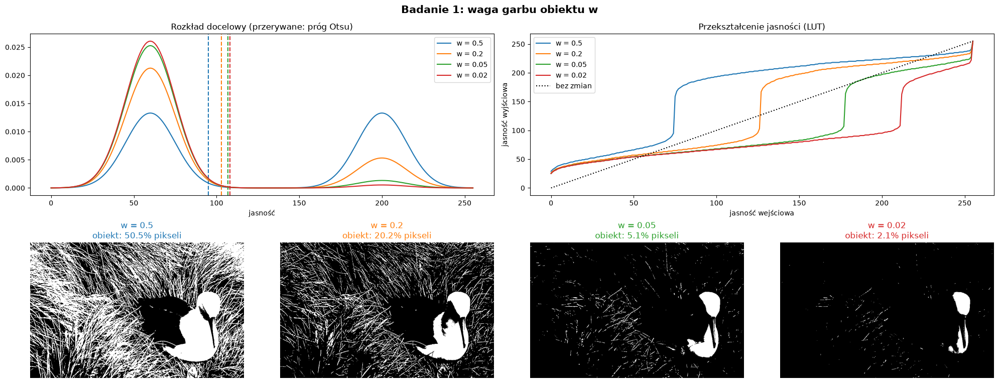

In [25]:
badaj_parametr(albatross_single, 'Badanie 1: waga garbu obiektu w',
               {f'w = {w}': two_peaks(w=w) for w in [0.5, 0.2, 0.05, 0.02]})

**Badanie 2: odległość między garbami** – środek między garbami stały (130), zmienia się `mu2 - mu1`

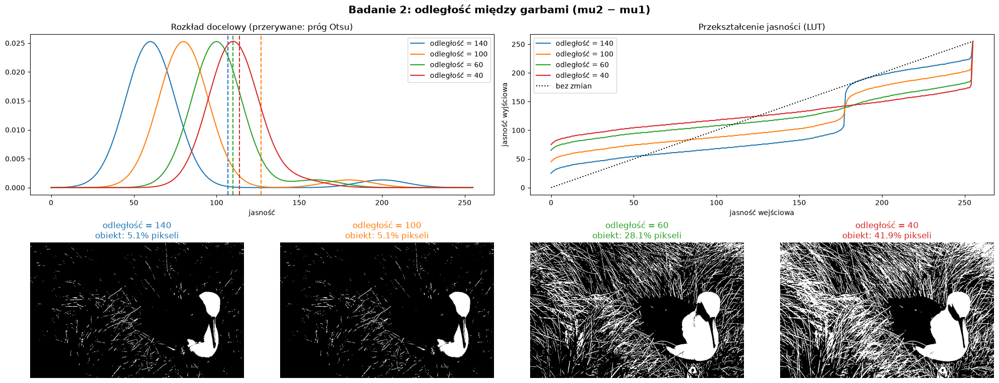

In [26]:
badaj_parametr(albatross_single, 'Badanie 2: odległość między garbami (mu2 − mu1)',
               {f'odległość = {d}': two_peaks(mu1=130 - d // 2, mu2=130 + d // 2) for d in [140, 100, 60, 40]})

**Badanie 3: szerokość garbu tła `sigma1`**

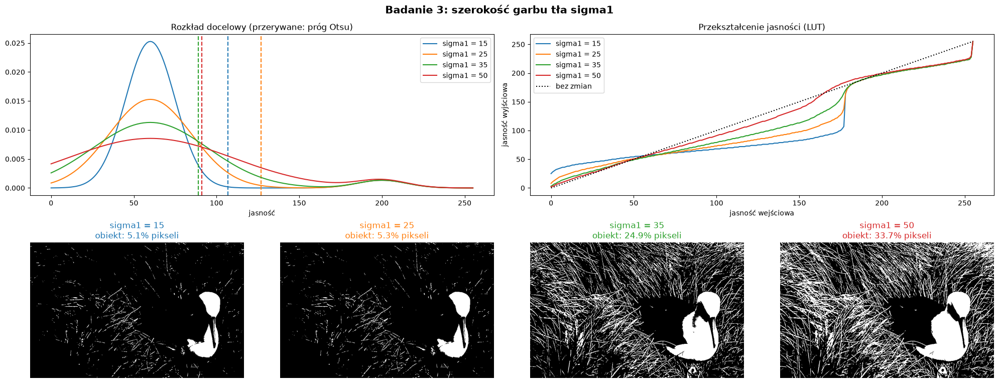

In [27]:
badaj_parametr(albatross_single, 'Badanie 3: szerokość garbu tła sigma1',
               {f'sigma1 = {s}': two_peaks(sigma1=s) for s in [15, 25, 35, 50]})

**Badanie 4: szerokość garbu obiektu `sigma2`**

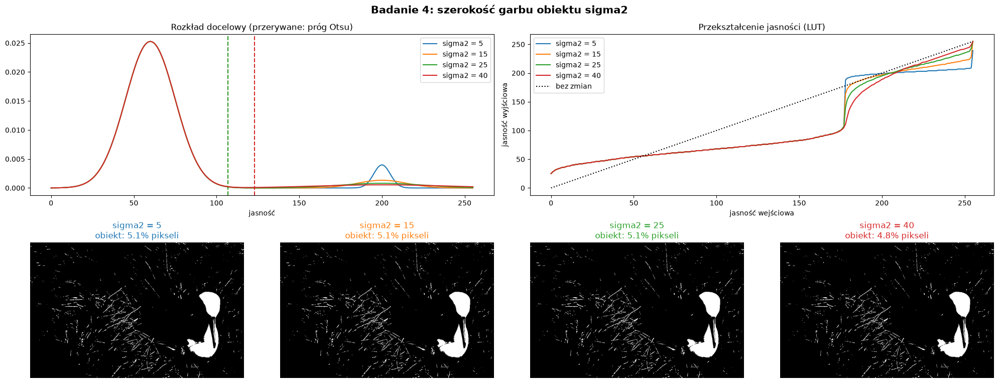

In [28]:
badaj_parametr(albatross_single, 'Badanie 4: szerokość garbu obiektu sigma2',
               {f'sigma2 = {s}': two_peaks(sigma2=s) for s in [5, 15, 25, 40]})

**Badanie 5: położenie garbów** – odległość między garbami stała (140), oba garby przesuwane razem

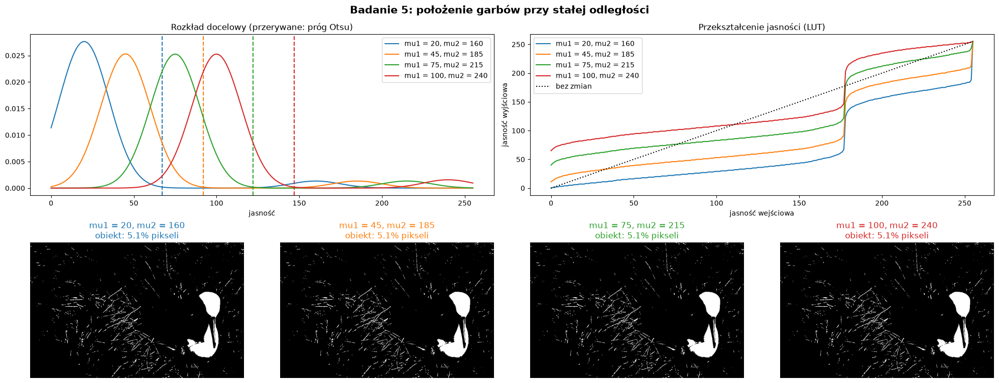

In [29]:
badaj_parametr(albatross_single, 'Badanie 5: położenie garbów przy stałej odległości',
               {f'mu1 = {m}, mu2 = {m + 140}': two_peaks(mu1=m, mu2=m + 140) for m in [20, 45, 75, 100]})

**`albatross_crowd` – dobór wagi `w`**

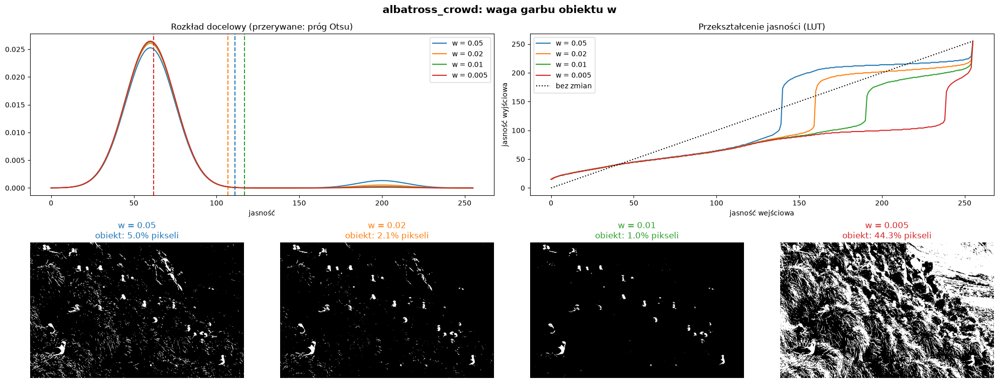

In [30]:
badaj_parametr(albatross_crowd, 'albatross_crowd: waga garbu obiektu w',
               {f'w = {w}': two_peaks(w=w) for w in [0.05, 0.02, 0.01, 0.005]})

**Wynik końcowy**

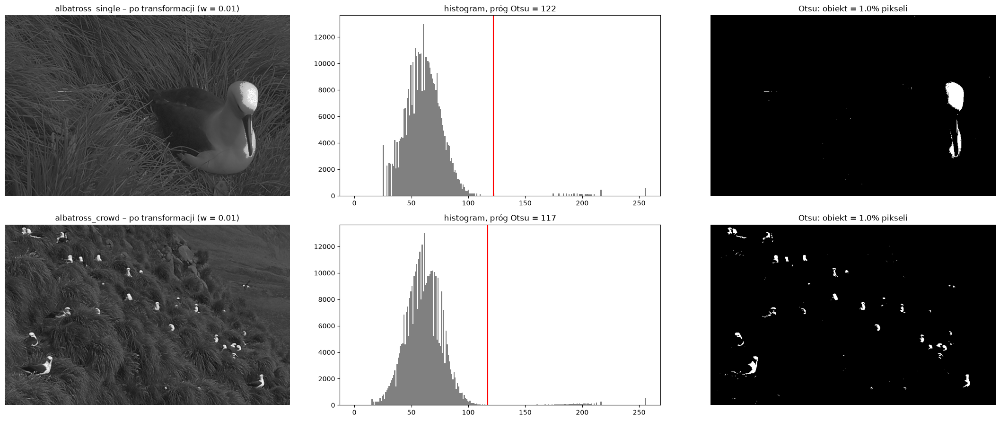

In [35]:
pokaz_otsu({
    'albatross_single – po transformacji (w = 0.01)': transform_hist(albatross_single, two_peaks(w=0.01)),
    'albatross_crowd – po transformacji (w = 0.01)': transform_hist(albatross_crowd, two_peaks(w=0.01)),
})

- w jest kluczowe. Odsetek pikseli uznanych przez Otsu za obiekt prawie równa się w (50.5 / 20.2 / 5.1 / 2.1%). Cała metoda działa więc w praktyce jak próg na kwantylu (1−w), a w musi odpowiadać faktycznemu udziałowi albatrosa.
- Garby muszą być rozdzielone. Przy odległości ≤60 albo sigma1 ≥35 zlewają się, Otsu tnie wewnątrz tła i wychodzi 25–42% „obiektu”.
- sigma2 i położenie garbów (przy stałej odległości) prawie nic nie zmieniają: wszędzie ok. 5.1%. Zmienia się tylko wygląd obrazu, a podział zostaje ten sam.
- crowd przy w = 0.005: garb obiektu jest tak mały, że Otsu go pomija i dzieli sam garb tła (próg ok. 62), co daje 44%. Za małe w też psuje wynik.